In [1]:
import pandas as pd

data_fp = "../../data/mces-data/biostructures.csv"
df = pd.read_csv(data_fp)
df

,smiles,inchi_key_1
0,C1COCCN1C2=NC(=NC(=N2)NC3=CC(=C(C=C3)C=CC4=C(C...,KFDYZSPFVRTLML
1,CCOC1=C(C=CC(=C1)C=NNC(=O)COC2=C(C=CC(=C2)C)C(...,HINREHSUCWWBNO
2,CCOC1=C(C=CC(=C1)C=NNC(=O)COC2=C(C=CC(=C2)C(C)...,XSJXTRKBEZABIM
3,CC1=CC=CC=C1N2C(=NN=C2SCC(=O)NC3=CC(=C(C=C3)Cl...,RGEDPHNWBSQUKZ
4,CC1=CC=CC=C1N2C(=NN=C2SCC(=O)NC3=C(C=CC=C3Cl)C...,RPFGFTBJBUHWDA
...,...,...
718092,CC(=O)OC1=C2C(=C3C(CN(C3=C1)C(=O)C4=CC5=CC(=C(...,FHZABVWOHCBVED
718093,CC(C)(C)C1=CC=C(C=C1)C2=NN=C(N2C3=CC=CC=C3)SCC...,MJYGYQSLIBPSCA
718094,CC(=NNC(=O)CSC1=NN=C(N1C2=CC=CC=C2)C3=CC=C(C=C...,BOBKKASWDWHSNN
718095,C1C[N+]2(CCC1C(C2)C(C3=CC=CC=C3)(C4=CC=CC=C4)O...,JHQFDHSPOYHZMH


In [2]:
# Check for duplicates by inchi_key_1
duplicates = df.duplicated(subset='inchi_key_1', keep=False)
print(f"Number of duplicated rows by inchi_key_1: {duplicates.sum()}")

# Show the duplicated entries
duplicated_df = df[duplicates].sort_values('inchi_key_1')
print(f"\nDuplicated entries:\n{duplicated_df}")

# Remove duplicates, keeping the first occurrence
df_dedup = df.drop_duplicates(subset='inchi_key_1', keep='first')
print(f"\nOriginal shape: {df.shape}")
print(f"After removing duplicates: {df_dedup.shape}")
print(f"Number of duplicates removed: {df.shape[0] - df_dedup.shape[0]}")

Number of duplicated rows by inchi_key_1: 0

Duplicated entries:
Empty DataFrame
Columns: [smiles, inchi_key_1]
Index: []

Original shape: (718097, 2)
After removing duplicates: (718097, 2)
Number of duplicates removed: 0


In [3]:
mol_df_fp = "../../data/mces-data/mol_df.pkl"
mol_df = pd.read_pickle(mol_df_fp)
mol_df

,smiles_org,idx,smiles,inchikey_s,scaffold,formula,inchi,mw,exact_mw,num_atoms,num_bonds,charge,single_mol,num_radicals,num_out_set_elements
0,C12C3(C4(C5C3(C(C1(C5(C2(C4(Cl)Cl)Cl)Cl)Cl)(Cl...,130,ClC1(Cl)C2(Cl)C3C4(Cl)C(Cl)(Cl)C5(Cl)C(C1(Cl)C...,DBAOHFBTAATJBT,C1C2C3C4CC5C3C1C5C24,C10H2Cl10,"InChI=1S/C10H2Cl10/c11-3-1-5(13)4(12)2(7(3,15)...",476.656,471.704177,20,24,0,True,0,0
1,C12(C3(C4(C5(C3(C(C1(C5(C2(C4(Cl)Cl)Cl)Cl)Cl)(...,131,ClC1(Cl)C2(Cl)C3(Cl)C4(Cl)C(Cl)(Cl)C5(Cl)C3(Cl...,GVYLCNUFSHDAAW,C1C2C3C4CC5C3C1C5C24,C10Cl12,"InChI=1S/C10Cl12/c11-1-2(12)7(17)4(14)3(13,5(1...",545.546,539.626232,22,26,0,True,0,0
2,C12(C3(C(C(C(C1(C(C(C(C2(F)F)(F)F)(F)F)(F)F)F)...,132,FC1(F)C(F)(F)C(F)(F)C2(F)C(F)(C1(F)F)C(F)(F)C(...,QKENRHXGDUPTEM,C1CCC2C(C1)CCC1CCCCC12,C14F24,"InChI=1S/C14F24/c15-1-2(16)4(18,10(29,30)14(37...",624.106,623.961677,38,40,0,True,0,0
3,C12(C(C3(C(C(C1(F)F)(C(C(C2(F)F)(C3(F)F)F)(F)F...,133,FC(F)(F)C12C(F)(F)C3(F)C(F)(F)C(F)(C1(F)F)C(F)...,LRMQIJUOLGKFKS,C1C2CC3CC1CC(C2)C3,C12F20,"InChI=1S/C12F20/c13-3-6(17,18)1(11(27,28)29)5(...",524.092,523.968064,32,34,0,True,0,0
4,C12C(C(C3C1O3)Cl)C4(C(=C(C2(C4(Cl)Cl)Cl)Cl)Cl)Cl,134,ClC1=C(Cl)C2(Cl)C3C4OC4C(Cl)C3C1(Cl)C2(Cl)Cl,ZXFXBSWRVIQKOD,C1=CC2CC1C1CC3OC3C21,C10H5Cl7O,InChI=1S/C10H5Cl7O/c11-3-1-2(4-5(3)18-4)9(15)7...,389.320,385.816009,18,21,0,True,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
58031,OS(=O)(=O)F,63413,O=S(=O)(O)F,UQSQSQZYBQSBJZ,,HFO3S,"InChI=1S/FHO3S/c1-5(2,3)4/h(H,2,3,4)",100.070,99.963043,5,4,0,True,0,0
58032,OS(=O)(=O)O,63415,O=S(=O)(O)O,QAOWNCQODCNURD,,H2O4S,"InChI=1S/H2O4S/c1-5(2,3)4/h(H2,1,2,3,4)",98.079,97.967380,5,4,0,True,0,0
58033,P(Cl)(Cl)(Cl)(Cl)Cl,63430,ClP(Cl)(Cl)(Cl)Cl,UHZYTMXLRWXGPK,,Cl5P,"InChI=1S/Cl5P/c1-6(2,3,4)5",208.239,205.818025,6,5,0,True,0,0
58034,[SiH2](Cl)Cl,63433,Cl[SiH2]Cl,MROCJMGDEKINLD,,H2Cl2Si,InChI=1S/Cl2H2Si/c1-3-2/h3H2,101.008,99.930282,3,2,0,True,0,0


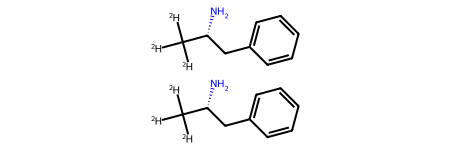

In [4]:
from rdkit import Chem
Chem.MolFromSmiles('[2H]C([2H])([2H])[C@@H](CC1=CC=CC=C1)N.[2H]C([2H])([2H])[C@@H](CC1=CC=CC=C1)N')  # Example to check RDKit functionality

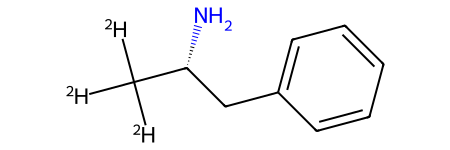

In [5]:
from fragnnet.utils.data_utils import mol_from_smiles
# Example to check if mol_from_smiles works correctly
mol = mol_from_smiles('[2H]C([2H])([2H])[C@@H](CC1=CC=CC=C1)N.[2H]C([2H])([2H])[C@@H](CC1=CC=CC=C1)N')
mol

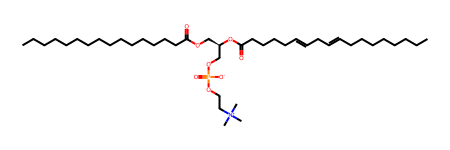

In [6]:
mol = mol_from_smiles('O=C(CCCCCCCCCCCCCCC)OC[C@H](COP(OCC[N+](C)(C)C)([O-])=O)OC(CCCC/C=C/C/C=C/CCCCCCCC)=O')
mol